In [28]:
# ============================================================
# 04 — RANDOM FOREST REGRESSION
# Gas Turbine Energy Yield and Emissions
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Locate dataset
DATA_DIR = Path("../data")

if not DATA_DIR.exists():
    DATA_DIR = Path("data")

files = sorted(DATA_DIR.glob("gt_*.csv"))

if not files:
    raise FileNotFoundError("Gas turbine CSV files not found.")

frames = []

for file in files:
    df = pd.read_csv(file)
    df["Year"] = int(file.stem.split("_")[-1])
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

feature_cols = [
    "AT", "AP", "AH", "AFDP",
    "GTEP", "TIT", "TAT", "CDP"
]

target_cols = ["TEY", "CO", "NOX"]

print("Dataset shape:", data.shape)
print("Years:", sorted(data["Year"].unique()))

Dataset shape: (36733, 12)
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]


In [29]:
# ============================================================
# TEMPORAL TRAIN / TEST SPLIT
# ============================================================

train_data = data[data["Year"] <= 2014].copy()
test_data = data[data["Year"] == 2015].copy()

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]

Y_train = train_data[target_cols]
Y_test = test_data[target_cols]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training years:", sorted(train_data["Year"].unique()))
print("Testing years:", sorted(test_data["Year"].unique()))

assert len(test_data) > 0
assert train_data["Year"].max() < test_data["Year"].min()

Training observations: 29349
Testing observations: 7384
Training years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
Testing years: [np.int64(2015)]


In [30]:
# ============================================================
# EVALUATION METRICS
# ============================================================

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [31]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH
# ============================================================

parameter_grid = {
    "n_estimators": [150, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [1.0, "sqrt"]
}

# Chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

print("Hyperparameter search space prepared.")
print("Cross-validation folds:", tscv.get_n_splits())

Hyperparameter search space prepared.
Cross-validation folds: 5


In [32]:
# ============================================================
# TRAIN RANDOM FOREST MODELS
# ============================================================

rf_models = {}
rf_cv_results = {}

rf_params = {
    "n_estimators": 100,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "max_features": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

for target in target_cols:

    print("\n" + "=" * 55)
    print("Training Random Forest for:", target)
    print("=" * 55)

    rf = RandomForestRegressor(**rf_params)

    # Train the model
    rf.fit(X_train, Y_train[target])

    # Store the trained model
    rf_models[target] = rf

    print("Training completed for:", target)

print("\nAll Random Forest models trained successfully.")


Training Random Forest for: TEY
Training completed for: TEY

Training Random Forest for: CO
Training completed for: CO

Training Random Forest for: NOX
Training completed for: NOX

All Random Forest models trained successfully.


In [33]:
# ============================================================
# RANDOM FOREST MODEL CONFIGURATION
# ============================================================

model_summary = pd.DataFrame([
    {
        "Target": target,
        "Model": "Random Forest",
        "Parameters": str(rf_models[target].get_params())
    }
    for target in target_cols
])

display(model_summary)

,Target,Model,Parameters
0,TEY,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
1,CO,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
2,NOX,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."


In [34]:
# ============================================================
# FINAL TEMPORAL TEST EVALUATION
# ============================================================

rf_results = []
rf_predictions = {}

for target in target_cols:

    model = rf_models[target]

    predictions = model.predict(X_test)

    rf_predictions[target] = predictions

    metrics = evaluate_model(
        Y_test[target],
        predictions
    )

    rf_results.append({
        "Model": "Random Forest",
        "Target": target,
        **metrics
    })

rf_results_df = pd.DataFrame(rf_results)

print("========== RANDOM FOREST TEST RESULTS ==========")

display(rf_results_df.round(4))

========== RANDOM FOREST TEST RESULTS ==========


,Model,Target,MAE,RMSE,R2
0,Random Forest,TEY,0.8587,1.1441,0.9950
1,Random Forest,CO,1.0069,1.5948,0.4908
2,Random Forest,NOX,9.1212,11.0834,0.0087


In [35]:
# ============================================================
# COMPARE BASELINES WITH RANDOM FOREST
# ============================================================

OUTPUT_DIR = Path("../outputs")

if not OUTPUT_DIR.exists():
    OUTPUT_DIR = Path("outputs")

baseline_path = OUTPUT_DIR / "baseline_temporal_results.csv"

if baseline_path.exists():

    baseline_results = pd.read_csv(baseline_path)

    combined_results = pd.concat(
        [baseline_results, rf_results_df],
        ignore_index=True
    )

    print("========== MODEL COMPARISON: 2015 ==========")

    display(
        combined_results
        .sort_values(["Target", "RMSE"])
        .round(4)
    )

else:

    print("Baseline result CSV not found.")
    print("Please copy baseline_temporal_results.csv into outputs.")

    combined_results = rf_results_df.copy()

========== MODEL COMPARISON: 2015 ==========


,Model,Target,MAE,RMSE,R2
10,Random Forest,CO,1.0069,1.5948,0.4908
7,Ridge Regression,CO,1.3388,1.8881,0.2862
4,Linear Regression,CO,1.3670,1.9241,0.2587
1,Mean Predictor,CO,1.3919,2.4276,-0.1800
5,Linear Regression,NOX,8.1810,10.2146,0.1580
8,Ridge Regression,NOX,8.2403,10.2731,0.1483
11,Random Forest,NOX,9.1212,11.0834,0.0087
2,Mean Predictor,NOX,11.1144,13.0245,-0.3690
9,Random Forest,TEY,0.8587,1.1441,0.9950
3,Linear Regression,TEY,1.2831,1.7910,0.9877


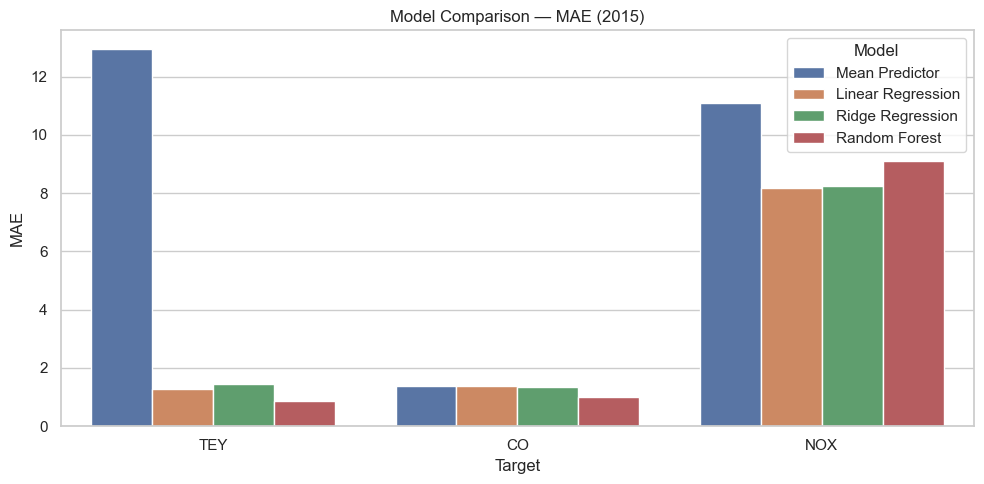

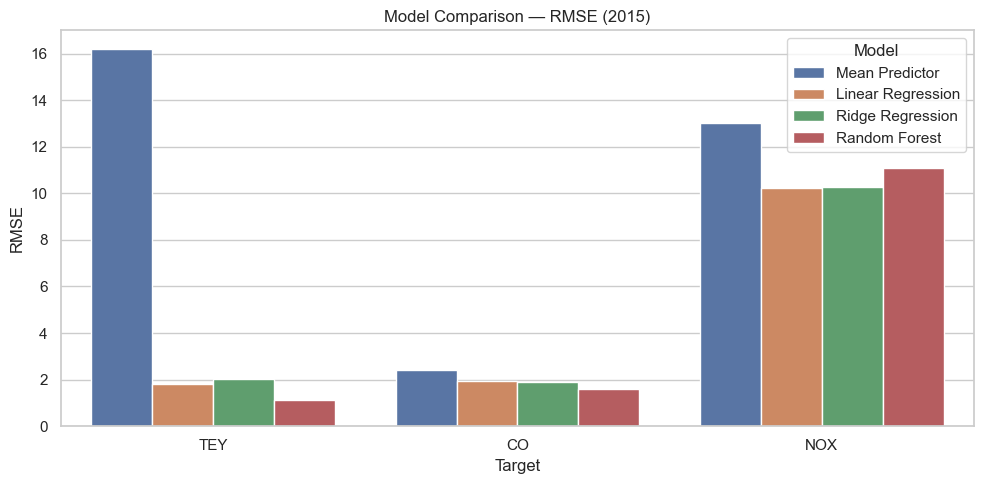

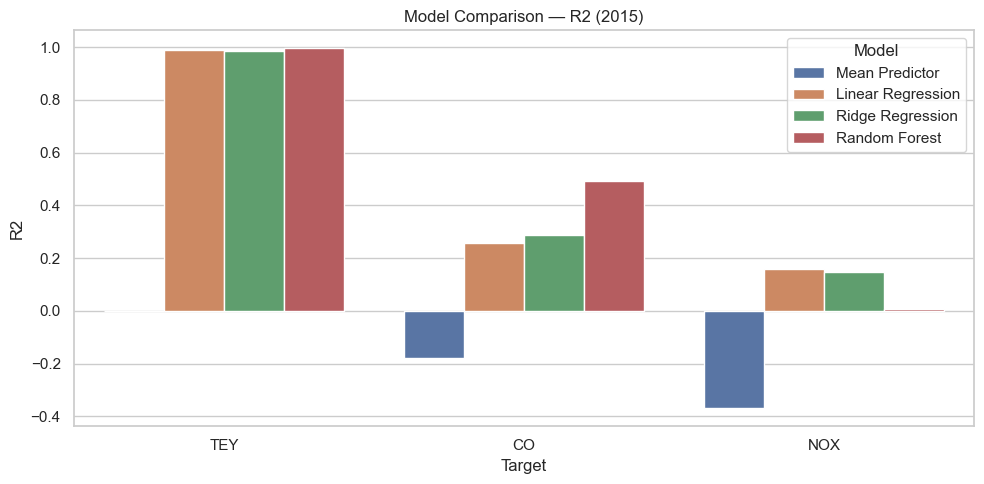

In [36]:
# ============================================================
# MODEL PERFORMANCE COMPARISON
# ============================================================

if "combined_results" in globals():

    for metric in ["MAE", "RMSE", "R2"]:

        plt.figure(figsize=(10, 5))

        sns.barplot(
            data=combined_results,
            x="Target",
            y=metric,
            hue="Model"
        )

        plt.title(f"Model Comparison — {metric} (2015)")
        plt.tight_layout()
        plt.show()

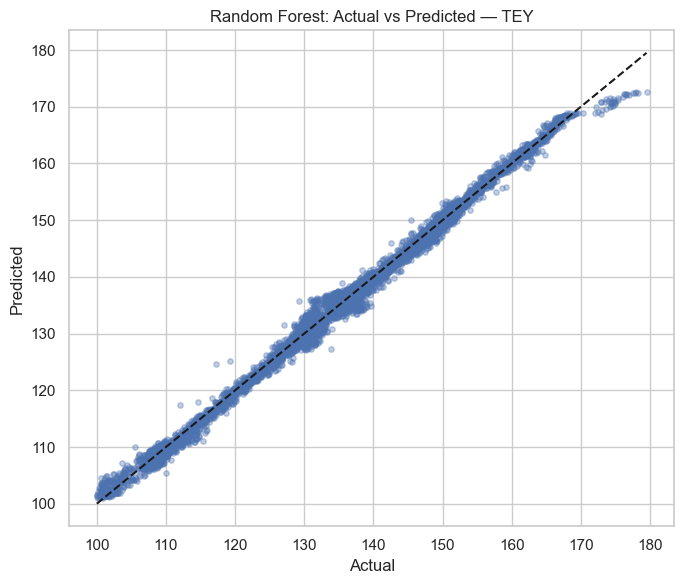

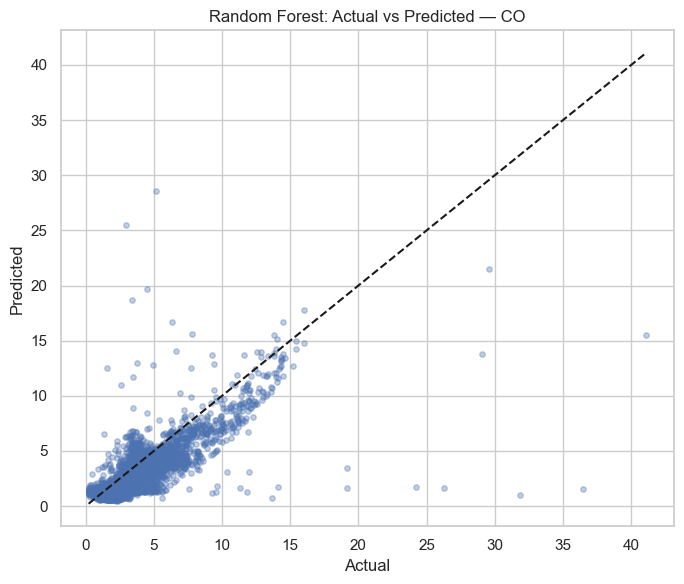

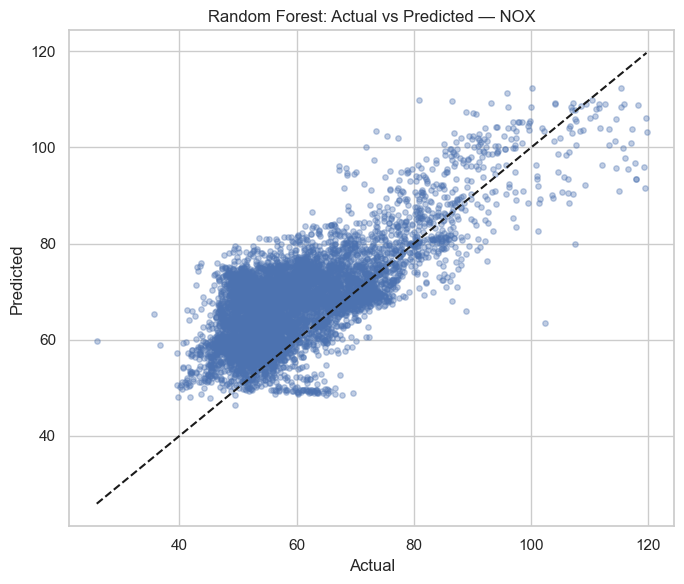

In [37]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in target_cols:

    actual = Y_test[target].values
    predicted = rf_predictions[target]

    plt.figure(figsize=(7, 6))

    plt.scatter(
        actual,
        predicted,
        alpha=0.35,
        s=15
    )

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    plt.plot(
        [lower, upper],
        [lower, upper],
        "k--"
    )

    plt.xlabel("Actual")
    plt.ylabel("Predicted")

    plt.title(f"Random Forest: Actual vs Predicted — {target}")

    plt.tight_layout()
    plt.show()

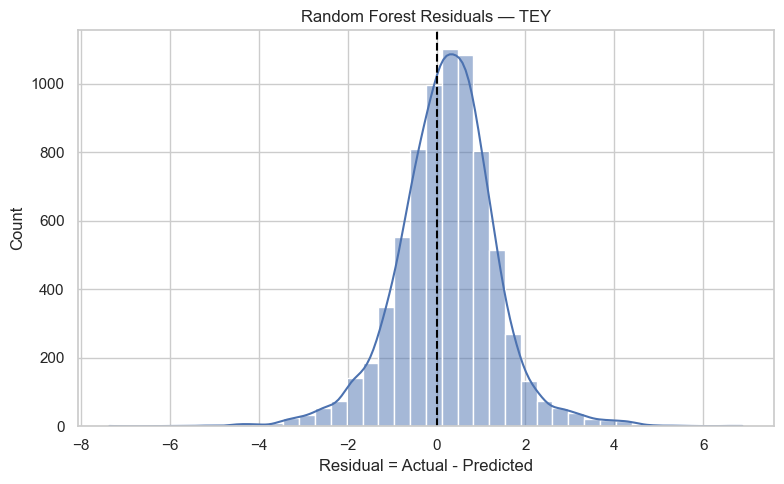

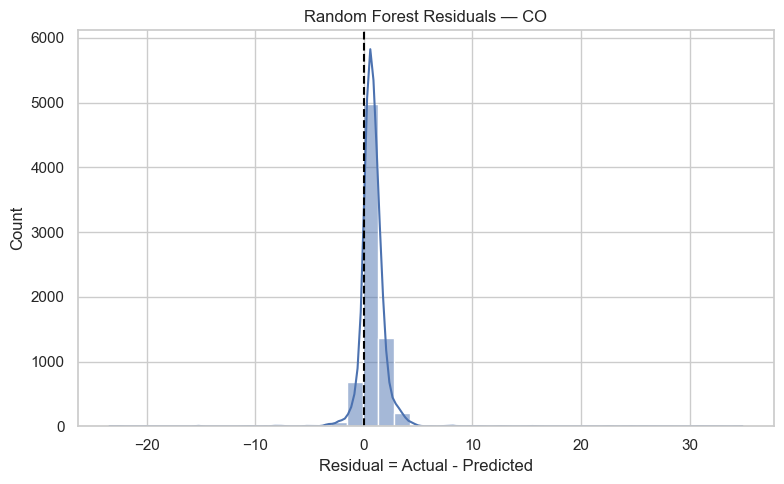

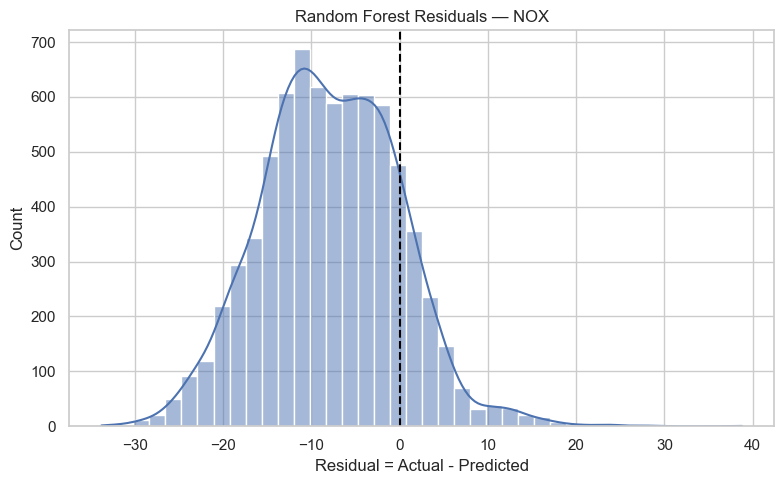

In [38]:
# ============================================================
# RESIDUAL DISTRIBUTIONS
# ============================================================

rf_residuals = {}

for target in target_cols:

    residuals = (
        Y_test[target].values - rf_predictions[target]
    )

    rf_residuals[target] = residuals

    plt.figure(figsize=(8, 5))

    sns.histplot(
        residuals,
        bins=40,
        kde=True
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--"
    )

    plt.title(f"Random Forest Residuals — {target}")
    plt.xlabel("Residual = Actual - Predicted")

    plt.tight_layout()
    plt.show()

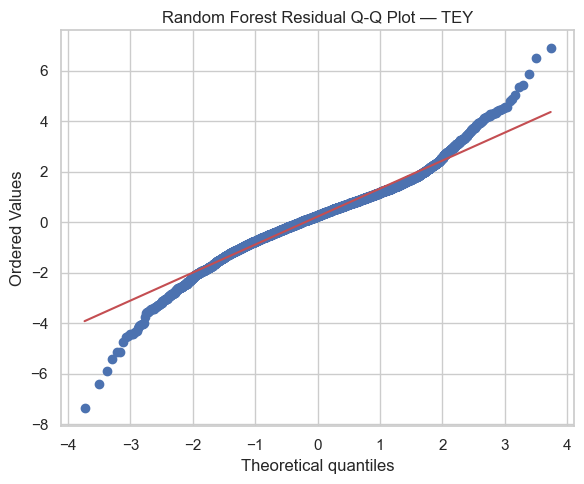

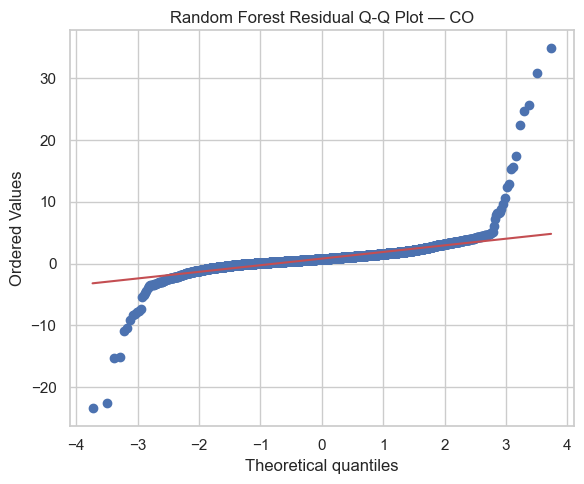

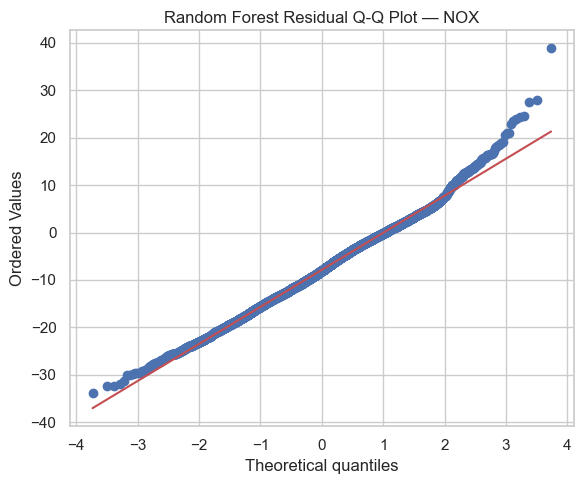

In [39]:
# ============================================================
# Q-Q PLOTS
# ============================================================

for target in target_cols:

    plt.figure(figsize=(6, 5))

    stats.probplot(
        rf_residuals[target],
        dist="norm",
        plot=plt
    )

    plt.title(f"Random Forest Residual Q-Q Plot — {target}")

    plt.tight_layout()
    plt.show()

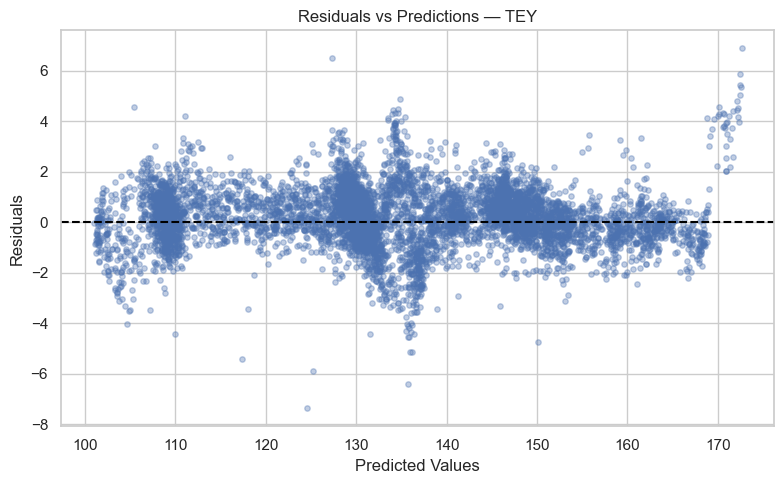

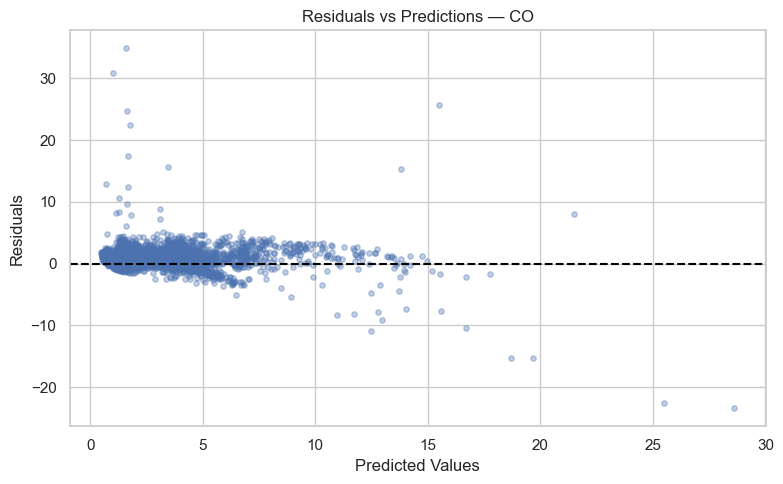

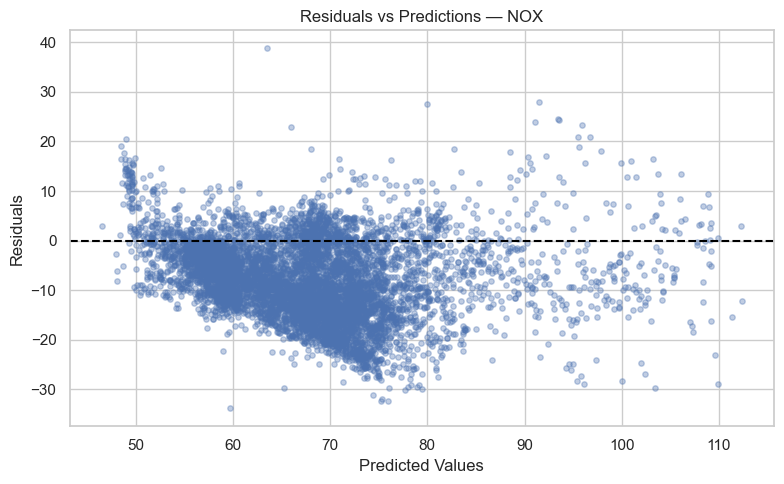

In [40]:
# ============================================================
# RESIDUALS VS PREDICTED VALUES
# ============================================================

for target in target_cols:

    plt.figure(figsize=(8, 5))

    plt.scatter(
        rf_predictions[target],
        rf_residuals[target],
        alpha=0.35,
        s=15
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--"
    )

    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")

    plt.title(f"Residuals vs Predictions — {target}")

    plt.tight_layout()
    plt.show()


Feature importance for TEY


,Feature,Importance
7,CDP,0.982083
0,AT,0.011546
5,TIT,0.003658
4,GTEP,0.001239
6,TAT,0.000584
3,AFDP,0.000401
1,AP,0.000281
2,AH,0.000207


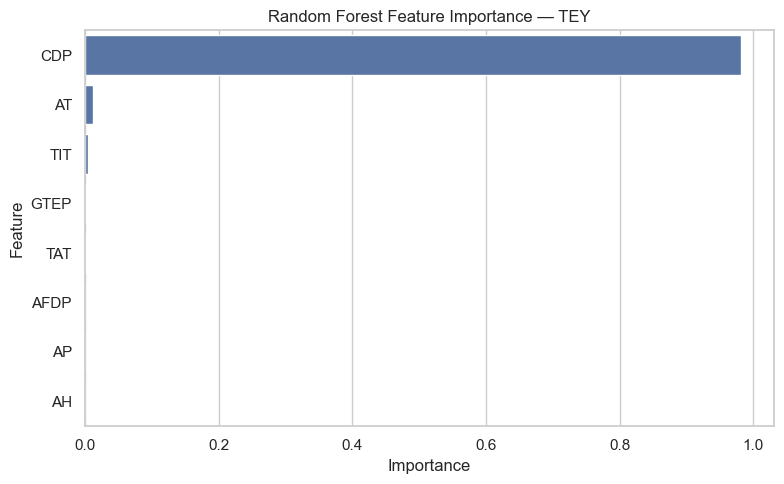


Feature importance for CO


,Feature,Importance
5,TIT,0.504201
6,TAT,0.247916
7,CDP,0.053544
3,AFDP,0.049563
4,GTEP,0.047663
0,AT,0.044407
1,AP,0.029995
2,AH,0.022711


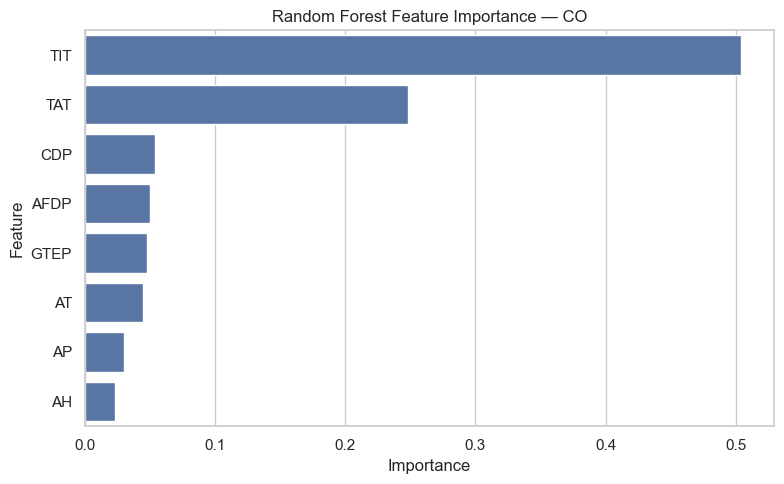


Feature importance for NOX


,Feature,Importance
0,AT,0.425010
5,TIT,0.161516
4,GTEP,0.125405
6,TAT,0.110256
3,AFDP,0.076301
2,AH,0.053159
1,AP,0.032645
7,CDP,0.015708


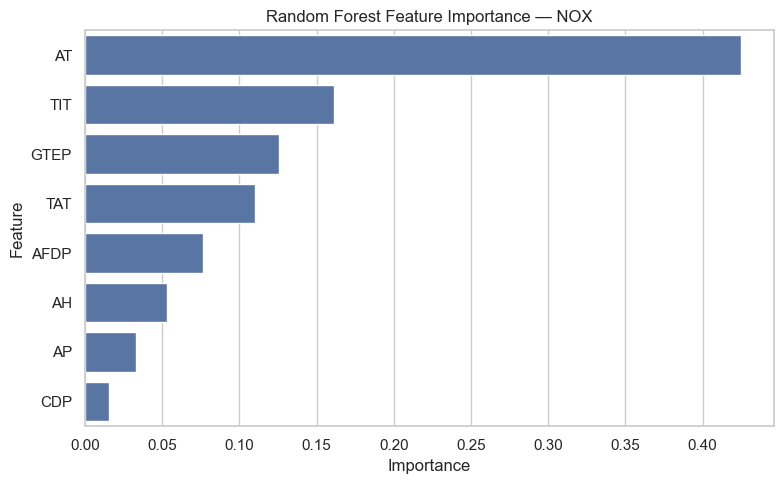

In [41]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

for target in target_cols:

    model = rf_models[target]

    importance = pd.DataFrame({
        "Feature": feature_cols,
        "Importance": model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    print(f"\nFeature importance for {target}")
    display(importance)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=importance,
        x="Importance",
        y="Feature"
    )

    plt.title(f"Random Forest Feature Importance — {target}")

    plt.tight_layout()
    plt.show()


Permutation importance — TEY


,Feature,Importance_Mean,Importance_Std
7,CDP,15.976035,0.107565
0,AT,1.916038,0.013037
5,TIT,0.908127,0.017779
4,GTEP,0.326218,0.012552
1,AP,0.020834,0.001705
6,TAT,0.020503,0.002459
2,AH,0.020318,0.000781
3,AFDP,0.013422,0.000689


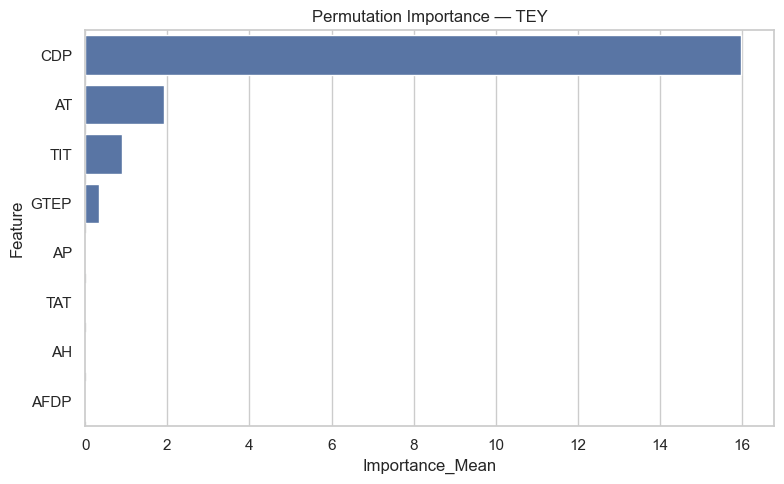


Permutation importance — CO


,Feature,Importance_Mean,Importance_Std
5,TIT,0.985826,0.020896
6,TAT,0.659503,0.021840
7,CDP,0.424227,0.006758
3,AFDP,0.046780,0.003217
4,GTEP,0.018172,0.003427
0,AT,0.011768,0.002439
2,AH,0.005801,0.001516
1,AP,-0.011731,0.001672


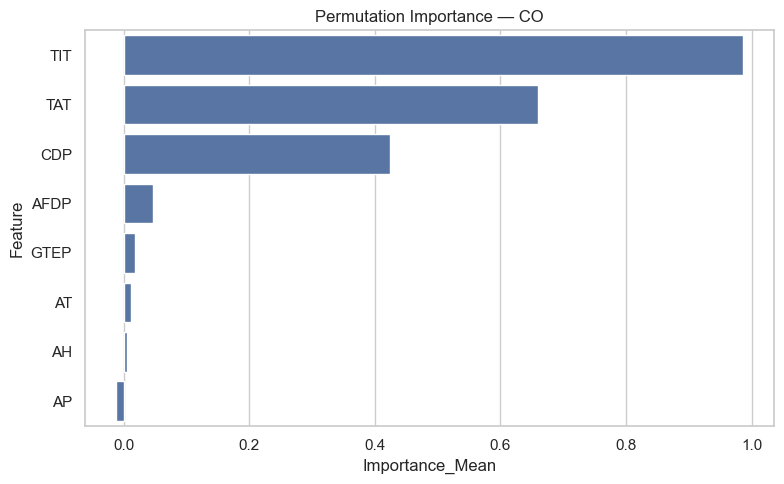


Permutation importance — NOX


,Feature,Importance_Mean,Importance_Std
0,AT,4.254189,0.040439
6,TAT,2.697020,0.039911
4,GTEP,1.807494,0.030385
5,TIT,1.657499,0.055790
7,CDP,0.189855,0.007987
1,AP,0.122549,0.016115
2,AH,0.058977,0.019329
3,AFDP,-0.068996,0.019336


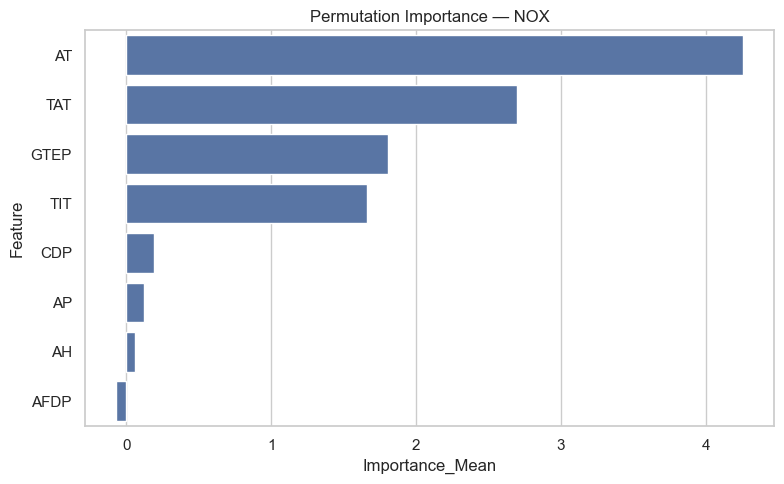

In [42]:
# ============================================================
# PERMUTATION IMPORTANCE
# ============================================================

permutation_results = {}

for target in target_cols:

    result = permutation_importance(
        rf_models[target],
        X_test,
        Y_test[target],
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance = pd.DataFrame({
        "Feature": feature_cols,
        "Importance_Mean": result.importances_mean,
        "Importance_Std": result.importances_std
    }).sort_values(
        "Importance_Mean",
        ascending=False
    )

    permutation_results[target] = importance

    print(f"\nPermutation importance — {target}")
    display(importance)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=importance,
        x="Importance_Mean",
        y="Feature"
    )

    plt.title(f"Permutation Importance — {target}")

    plt.tight_layout()
    plt.show()

In [43]:
# ============================================================
# SAVE RANDOM FOREST RESULTS
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rf_results_df.to_csv(
    OUTPUT_DIR / "random_forest_temporal_results.csv",
    index=False
)

model_summary.to_csv(
    OUTPUT_DIR / "random_forest_model_configuration.csv",
    index=False
)

if "combined_results" in globals():
    combined_results.to_csv(
        OUTPUT_DIR / "all_models_comparison.csv",
        index=False
    )

rf_prediction_output = test_data[["Year"]].copy()

for target in target_cols:

    rf_prediction_output[f"{target}_actual"] = (
        Y_test[target].values
    )

    rf_prediction_output[f"{target}_random_forest"] = (
        rf_predictions[target]
    )

rf_prediction_output.to_csv(
    OUTPUT_DIR / "random_forest_2015_predictions.csv",
    index=False
)

print("Random Forest outputs saved successfully!")

print("\nFiles saved:")
print("1. random_forest_temporal_results.csv")
print("2. random_forest_model_configuration.csv")
print("3. all_models_comparison.csv")
print("4. random_forest_2015_predictions.csv")

Random Forest outputs saved successfully!

Files saved:
1. random_forest_temporal_results.csv
2. random_forest_model_configuration.csv
3. all_models_comparison.csv
4. random_forest_2015_predictions.csv
